<a href="https://colab.research.google.com/github/23jaikav/IS-4487/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
df = pd.read_csv('/content/cleaned_airbnb_data_6.csv')
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1733333348320050763,https://www.airbnb.com/rooms/1733333348320050763,20260919134159,2026-09-20,NaN,Schöne Souterrain Wohnung unweit vom Ku'damm,Enjoy the simple life in this quiet and centra...,https://a0.muscache.com/pictures/hosting/Hosti...,1729156025960279337,https://www.airbnb.com/users/show/172915602596...,...,5.0,5.0,4.0,04/Z/AZ/017613-25,NaN,1,1,0,0,1.00
1,811527740012470418,https://www.airbnb.com/rooms/811527740012470418,20260919134159,2026-09-20,NaN,Moderne Wohnung in Top-Lage,The whole group will enjoy easy access to ever...,https://a0.muscache.com/pictures/hosting/Hosti...,366280303,https://www.airbnb.com/users/show/366280303,...,NaN,NaN,NaN,First name and Last name: Arthur Joselowitsch ...,NaN,1,1,0,0,NaN
2,638045311043310955,https://www.airbnb.com/rooms/638045311043310955,20260919134159,2026-09-20,NaN,Berlin - Neukölln - 2 bedroom flat,Well divided and spacious flat for families in...,https://a0.muscache.com/pictures/miso/Hosting-...,37827150,https://www.airbnb.com/users/show/37827150,...,5.0,4.4,4.4,08/Z/RA/012501-23,NaN,1,1,0,0,0.12
3,20842113,https://www.airbnb.com/rooms/20842113,20260919134159,2026-09-20,previous scrape,Cosy Bright Room in Kreuzberg,"Cosy, bright room right in the heart of Kreuzb...",https://a0.muscache.com/pictures/793a5224-740a...,15510261,https://www.airbnb.com/users/show/15510261,...,5.0,5.0,5.0,NaN,NaN,2,0,2,0,0.02
4,20833362,https://www.airbnb.com/rooms/20833362,20260919134159,2026-09-20,previous scrape,Quiet room in lively area.,3 minutes walk from U-bahn Karl-Marx-Str (U7)....,https://a0.muscache.com/pictures/2adf4b44-204d...,8677751,https://www.airbnb.com/users/show/8677751,...,5.0,NaN,NaN,NaN,NaN,1,0,1,0,0.01


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

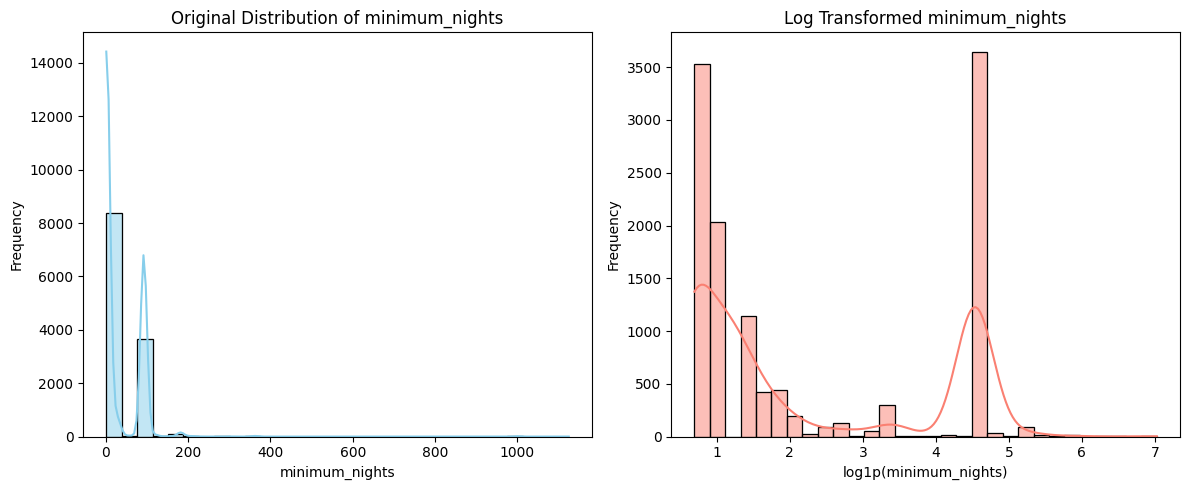

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Selecting a commonly skewed numerical column in Airbnb datasets, like 'minimum_nights' or 'price'
# Let's inspect the distribution of 'minimum_nights' as it often has highly skewed values.
column_to_transform = 'minimum_nights'

# Filter out missing values for plotting
data_to_plot = df[column_to_transform].dropna()

# Create a figure with 1 row and 2 columns
plt.figure(figsize=(12, 5))

# Subplot 1: Original Distribution
plt.subplot(1, 2, 1)
sns.histplot(data_to_plot, bins=30, kde=True, color='skyblue')
plt.title(f'Original Distribution of {column_to_transform}')
plt.xlabel(column_to_transform)
plt.ylabel('Frequency')

# Apply a Log Transformation (using log1p to handle zero values safely if any exist)
df['log_' + column_to_transform] = np.log1p(df[column_to_transform])

transformed_data_to_plot = df['log_' + column_to_transform].dropna()

# Subplot 2: Log Transformed Distribution
plt.subplot(1, 2, 2)
sns.histplot(transformed_data_to_plot, bins=30, kde=True, color='salmon')
plt.title(f'Log Transformed {column_to_transform}')
plt.xlabel(f'log1p({column_to_transform})')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. The column I examined was minimum nights.

2. I did a log transformation to make it easier to analyze, since the scale is smaller and more representative of the data.

3. The transformed version helped make the data more usable for analysis or stakeholder review because it reveals hidden patterns.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [6]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-Max scaling
minmax = MinMaxScaler()
df['price_scaled'] = minmax.fit_transform(df[['price']])

# Z-score standardization
standard = StandardScaler()
df['minimum_nights_zscore'] = standard.fit_transform(df[['minimum_nights']])

# Compare original and transformed columns
df[['price', 'price_scaled',
    'minimum_nights', 'minimum_nights_zscore']].describe()


,price,price_scaled,minimum_nights,minimum_nights_zscore
count,8157.000000,8157.000000,12233.000000,1.223300e+04
mean,167.564032,0.015452,33.350282,-1.022280e-16
std,191.783955,0.019155,52.247585,1.000041e+00
min,12.860000,0.000000,1.000000,-6.191981e-01
25%,81.140000,0.006820,1.000000,-6.191981e-01
50%,129.500000,0.011650,3.000000,-5.809172e-01
75%,203.000000,0.018991,92.000000,1.122580e+00
max,10025.000000,1.000000,1125.000000,2.089464e+01



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I scaled price using MinMaxScaler, which transformed the values to a range of 0 to 1. I used StandardScaler on minimum_nights, which converted the values into Z-scores.

2. The scaled values are more useful than the originals when we are building machine learning models are comparing variables that have different ranges.

3. The data anlalysts at Airbnb and pricing team could benefit from this transformation because they make it easier to compare listing prices and minimum stay requirements.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [8]:
# Add code here 🔧
df['review_category'] = pd.cut(
    df['number_of_reviews'],
    bins=[-1, 20, 100, float('inf')],
    labels=['Low', 'Medium', 'High']
)

df[['number_of_reviews', 'review_category']].head()
df['review_category'].value_counts()

,count
review_category,
Low,7102
Medium,3221
High,2053


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. The column I grouped was number of reviews into 3 categories.

2. Someone might prefer this grouped view over raw numbers because they make it easier to identify patterns and compare listings, without having to look at each individual one.

3. This would help the marketing team because it allows them to quickly identify listings with different levels of review activity.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [9]:
# Minimum cost of booking a listing
df['minimum_stay_cost'] = df['price'] * df['minimum_nights']

# Flag listings that require more than 30 nights
df['long_term_stay'] = (df['minimum_nights'] > 30).astype(int)

# Preview the new columns
df[['price', 'minimum_nights',
    'minimum_stay_cost', 'long_term_stay']].head()

,price,minimum_nights,minimum_stay_cost,long_term_stay
0,97.0,3.0,291.0,0
1,69.6,1.0,69.6,0
2,219.0,5.0,1095.0,0
3,NaN,92.0,NaN,1
4,NaN,92.0,NaN,1


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created minimum stay cost to help customers quickly understand the total minimum cost of booking a listing. I created long term stay to make it easier to identify listings that are intended for longer stays.

2. Airbnb hosts, property managers, and customers could use these variables.

3. These variables could help customers compare the minimum cost of different listings and help hosts make better decisions about pricing and minimum stay requirements. Airbnb could also use them to improve listing recommendations.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [10]:
# One-hot encode room type
df = pd.get_dummies(df, columns=['room_type'],
                    prefix='room', dtype=int)

# Preview the new columns
df.filter(like='room_').head()

,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,1,0,0,0
1,1,0,0,0
2,1,0,0,0
3,0,0,1,0
4,0,0,1,0


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. The column I encoded is room type because different types of Airbnb listings may influence customer booking decisions.
2. I used one-hot encoding.
3. This transformation could help a price model identify how different room types, affect a listing's price.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [12]:
# export csv here 🔧
df.to_csv('cleaned_airbnb_data_7.csv', index=False)

## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. The transformation step that felt most important or interesting to me is one-hot encoding. Changing categorical variables to numeric ones can be very useful for analysis.

2. I think minimum stay cost would be most useful to Airbnb hosts because it helps them understand the minimum booking costs.

3. If I were going to build a tool or dashboard, I would compare listing prices, minimum stay requirements, and review activity across different neighborhoods.

4. This relates to my customized learning outcomes I created in canvas because I practiced cleaning and transforming data in Python to make it more useful for analysis. I also learned how to turn raw data into meaningful variables that could help answer business questions and support better decisions.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [14]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"

[NbConvertApp] Converting notebook assignment_07_data_transformation.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 410380 bytes to assignment_07_data_transformation.html
